# Land Cover

Gets MODIS, NLCD, and performs the crosswalk

In [1]:
%matplotlib ipympl

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# setting up logging first or else it gets preempted by another package
import watershed_workflow
watershed_workflow.setupLogging(1)

In [4]:
import os,sys
import logging
import numpy as np
from matplotlib import pyplot as plt
import pickle
import shapely
import pandas as pd
import geopandas as gpd
import xarray as xr
pd.options.display.max_columns = None

import cftime
import datetime

import watershed_workflow 
import watershed_workflow.utils
import watershed_workflow.sources
import watershed_workflow.mesh
import watershed_workflow.properties.land_cover
import watershed_workflow.io

# set the default figure size for notebooks
plt.rcParams["figure.figsize"] = (8, 6)

## Input: Parameters and other source data

In [5]:
# Force Watershed Workflow to pull data from this directory rather than a shared data directory.
# This picks up the Coweeta-specific datasets set up here to avoid large file downloads for 
# demonstration purposes.
#
def splitPathFull(path):
    """
    Splits an absolute path into a list of components such that
    os.path.join(*splitPathFull(path)) == path
    """
    parts = []
    while True:
        head, tail = os.path.split(path)
        if head == path:  # root on Unix or drive letter with backslash on Windows (e.g., C:\)
            parts.insert(0, head)
            break
        elif tail == path:  # just a single file or directory
            parts.insert(0, tail)
            break
        else:
            parts.insert(0, tail)
            path = head
    return parts

cwd = splitPathFull(os.getcwd())
assert cwd[-1] == 'workflow'
cwd = cwd[:-1]

# Note, this directory is where downloaded data will be put as well
data_dir = os.path.join(*(cwd + ['input_data',]))
def toInput(filename):
    return os.path.join(data_dir, filename)

output_filenames = dict()
output_dir = os.path.join(*(cwd + ['output_data',]))
def fromOutput(filename):
    return os.path.join(output_dir, filename)    

def toOutput(role, filename):
    output_filenames[role] = filename
    return fromOutput(filename)

# check output and input dirs exist
if not os.path.isdir(data_dir):
    os.makedirs(data_dir, exist_ok=True)
if not os.path.isdir(output_dir):
    os.makedirs(output_dir, exist_ok=True)
       

In [6]:
# Set the data directory to the local space to get the locally downloaded files
# REMOVE THIS CELL for general use outside fo Coweeta
print(data_dir)
watershed_workflow.utils.setDataDirectory(data_dir)


/Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/input_data


In [7]:
## Parameters cell -- this provides all parameters that can be changed via pipelining to generate a new watershed. 
name = 'RussianRiver'
hucs = ['18010110'] # a list of HUCs to run

# Geometric parameters
# -- parameters to clean and reduce the river network prior to meshing
prune_by_area = 10               # km^2
simplify = 125                   # length scale to target average edge 

# -- mesh triangle refinement control
refine_d0 = 200
refine_d1 = 600

refine_L0 = 125
refine_L1 = 300

refine_A0 = refine_L0**2 / 2
refine_A1 = refine_L1**2 / 2

# Refine triangles if they get too acute
min_angle = 20 # degrees

# width of reach by stream order (order:width)
river_widths = dict({1:10, 2:10, 3:20, 4:30, 5:30}) 


# Note that, by default, we tend to work in the DayMet CRS because this allows us to avoid
# reprojecting meteorological forcing datasets.
crs = watershed_workflow.crs.default_crs


# start and stop time for simulation
# note that this is the overlap of AORC and MODIS
start = cftime.DatetimeGregorian(2007, 8, 1)
end = cftime.DatetimeGregorian(2020, 12, 31)

start_noleap = cftime.DatetimeNoLeap(2007, 8, 1)
end_noleap = cftime.DatetimeNoLeap(2020, 12, 31)
cyclic_nyears = 10


In [8]:
# set up a dictionary of source objects
#
# Data sources, also called managers, deal with downloading and parsing data files from a variety of online APIs.
sources = watershed_workflow.sources.getDefaultSources()

# log the sources that will be used here
watershed_workflow.sources.logSources(sources)


2026-11-10 13:15:02,237 - root - INFO: Using sources:
2026-11-10 13:15:02,237 - root - INFO: --------------
2026-11-10 13:15:02,237 - root - INFO: HUC: ManagerWBD
2026-11-10 13:15:02,237 - root - INFO: hydrography: ManagerNHD
2026-11-10 13:15:02,237 - root - INFO: DEM: Manager3DEP
2026-11-10 13:15:02,238 - root - INFO: soil structure: ManagerNRCS
2026-11-10 13:15:02,238 - root - INFO: geologic structure: ManagerGLHYMPS
2026-11-10 13:15:02,238 - root - INFO: depth to bedrock: ManagerPelletierDTB
2026-11-10 13:15:02,238 - root - INFO: land cover: ManagerNLCD
2026-11-10 13:15:02,238 - root - INFO: LAI: ManagerMODISEarthdata
2026-11-10 13:15:02,239 - root - INFO: meteorology: ManagerAORC
2026-11-10 13:15:02,239 - root - INFO: evapotranspiration: ManagerSSEBop
2026-11-10 13:15:02,239 - root - INFO: observations: ManagerNWIS


## Reload data

In [9]:
with open(fromOutput('02_watersheds.pickle'), 'rb') as fid:
    watersheds = pickle.load(fid)

In [10]:
watersheds.df.to_crs(watershed_workflow.crs.latlon_crs).bounds

,minx,miny,maxx,maxy
0,-123.387615,38.30068,-122.52954,39.398893


In [11]:
with open(fromOutput('03d_m2.pickle'), 'rb') as fid:
    m2 = pickle.load(fid)


In [12]:
# also load a reference watershed, which will be used to download the data -- this data is already downloaded
# so saves us from small wiggles requiring a new download
#
# Note, in this workflow the reference watershed is the watershed, and wiggles should no longer be a problem
ref_watershed = watersheds.df

## Get NLCD data

In [13]:
# download the NLCD raster
nlcd = sources['land cover'].getDataset(ref_watershed)['cover']

# what land cover types did we get?
logging.info('Found land cover dtypes: {}'.format(nlcd.dtype))
logging.info('Found land cover types: {}'.format(set(nlcd.values.ravel())))

2026-11-10 13:15:03,621 - root - INFO: Incoming shape area = 0.39878167629126127
2026-11-10 13:15:03,621 - root - INFO: ... buffering incoming shape by 3x native resolution = 0.00081
2026-11-10 13:15:03,624 - root - INFO: ... buffered shape area = 0.40248074002008327
2026-11-10 13:15:03,624 - root - INFO: ManagerNLCD: cache hit at /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/input_data/land_cover/NLCD_L48_2021/pygeohydro_mrlc/pygeohydro_mrlc_-123.3886_38.2998_-122.5287_39.3997
2026-11-10 13:15:03,981 - root - INFO: Found land cover dtypes: int16
2026-11-10 13:15:04,233 - root - INFO: Found land cover types: {np.int16(71), np.int16(41), np.int16(42), np.int16(43), np.int16(11), np.int16(81), np.int16(82), np.int16(52), np.int16(21), np.int16(22), np.int16(23), np.int16(24), np.int16(90), np.int16(31), np.int16(-1), np.int16(95)}


In [14]:
nlcd

<xarray.DataArray 'cover' (y: 4070, x: 2508)> Size: 20MB
array([[-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       ...,
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1]], shape=(4070, 2508), dtype=int16)
Coordinates:
  * y            (y) float64 33kB 38.3 38.3 38.3 38.3 ... 39.4 39.4 39.4 39.4
  * x            (x) float64 20kB -123.4 -123.4 -123.4 ... -122.5 -122.5 -122.5
    spatial_ref  int64 8B 0
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area
    units:                   classes
    _FillValue:              -1

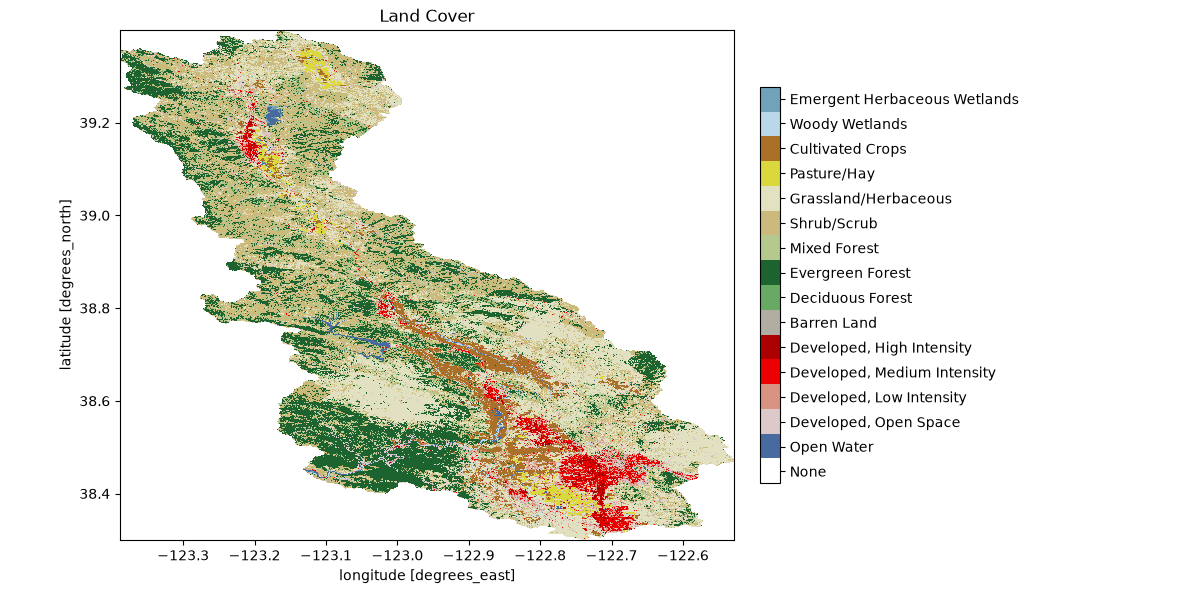

In [15]:
# create a colormap for the data
nlcd_indices, nlcd_cmap, nlcd_norm, nlcd_ticks, nlcd_labels = \
      watershed_workflow.plot.createNLCDColormap(np.unique(nlcd))

fig = plt.figure(figsize=(12,6))
ax = fig.add_axes([0.1, 0.1, 0.55, 0.85])

nlcd.plot.imshow(ax=ax, cmap=nlcd_cmap, norm=nlcd_norm, add_colorbar=False)
watershed_workflow.plot.createIndexedColorbar(ncolors=len(nlcd_indices), 
                               cmap=nlcd_cmap, labels=nlcd_labels, norm=nlcd_norm, ax=ax) 
ax.set_title('Land Cover')
plt.show()


In [16]:
# map nlcd onto the mesh
m2_nlcd = watershed_workflow.getDatasetOnMesh(m2, nlcd, method='nearest')
m2.cell_data['land_cover'] = m2_nlcd
m2_nlcd

<xarray.DataArray 'cover' (points: 415270)> Size: 831kB
array([42, 43, 52, ..., 52, 52, 43], shape=(415270,), dtype=int16)
Coordinates:
    x            (points) float64 3MB -123.1 -123.1 -123.1 ... -122.7 -122.7
    y            (points) float64 3MB 39.15 39.15 39.15 ... 38.66 38.65 38.65
    spatial_ref  int64 8B 0
Dimensions without coordinates: points
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area
    units:                   classes
    _FillValue:              -1

In [17]:
# double-check that nan not in the values
assert 127 not in m2_nlcd
assert 0 not in m2_nlcd

# create a new set of labels and indices with only those that actually appear on the mesh
nlcd_indices, nlcd_cmap, nlcd_norm, nlcd_ticks, nlcd_labels = \
      watershed_workflow.plot.createNLCDColormap(np.unique(m2_nlcd))

print("NLCD")
print("Index\t\tName")
print("----------------------------------------------")
for i,l in zip(nlcd_indices, nlcd_labels):
    print(f"{i}\t\t{l}")

NLCD
Index		Name
----------------------------------------------
11		Open Water
21		Developed, Open Space
22		Developed, Low Intensity
23		Developed, Medium Intensity
24		Developed, High Intensity
31		Barren Land
41		Deciduous Forest
42		Evergreen Forest
43		Mixed Forest
52		Shrub/Scrub
71		Grassland/Herbaceous
81		Pasture/Hay
82		Cultivated Crops
90		Woody Wetlands
95		Emergent Herbaceous Wetlands


In [18]:
# add labeled sets to the mesh for NLCD
nlcd_labels_dict = dict(zip(nlcd_indices, nlcd_labels))
watershed_workflow.mesh.addSurfaceRegions(m2, names=nlcd_labels_dict)

In [19]:
print("labeled sets")
print(f"label\tname\tcount")
for ls in m2.labeled_sets:
    print(f"{ls.setid}\t{ls.name}\t{len(ls.ent_ids)}")

labeled sets
label	name	count
10000	outlet	1
10001	Russian	415270
10002	Russian surface	415270
10003	Russian boundary	1903
10004	Russian outlet	9
10005	surface domain outlet	9
10006	stream order 5	1338
10007	stream order 1	14540
10008	stream order 2	4886
10009	stream order 4	944
10010	stream order 3	2756
10011	USGS-11461000	3
10012	USGS-11461000 cells	3
10013	USGS-11461500	3
10014	USGS-11461500 cells	3
10015	USGS-11462000	3
10016	USGS-11462000 cells	3
10017	USGS-11462080	3
10018	USGS-11462080 cells	3
10019	USGS-11462500	3
10020	USGS-11462500 cells	3
10021	USGS-11463000	3
10022	USGS-11463000 cells	3
10023	USGS-11463170	3
10024	USGS-11463170 cells	3
10025	USGS-11463200	3
10026	USGS-11463200 cells	3
10027	USGS-11463500	3
10028	USGS-11463500 cells	3
10029	USGS-11463682	3
10030	USGS-11463682 cells	3
10031	USGS-11463900	3
10032	USGS-11463900 cells	3
10033	USGS-11463980	3
10034	USGS-11463980 cells	3
10035	USGS-11464000	3
10036	USGS-11464000 cells	3
10037	USGS-11465000	3
10038	USGS-11465000 ce

In [20]:
lc_lss = [ls for ls in m2.labeled_sets if ls.setid >= 11 and ls.setid < 100]
print('total counts = ', sum(len(ls.ent_ids) for ls in lc_lss))
print('mesh cells = ', m2.num_cells)
print('unique counts = ', len(np.unique(np.concatenate([ls.ent_ids for ls in lc_lss]))))
        

total counts =  415270
mesh cells =  415270
unique counts =  415270


In [21]:
# write the mesh to disk with new NLCD labels
with open(toOutput('m2', '04_m2.pickle'), 'wb') as fid:
    pickle.dump(m2, fid)


In [22]:
# get default properties
nlcd_props = watershed_workflow.properties.land_cover.getDefaultProperties(nlcd_labels_dict.keys())                                                                           
                                                                           

In [23]:
# save properties to disk
nlcd_props.to_csv(toOutput('land_cover_properties', '04_land_cover_properties.csv'))

## MODIS LAI

Leaf area index is needed on each land cover type -- this is used in the Evapotranspiration calculation.

### Download

In [24]:
# download LAI and corresponding LULC datasets
#
# get the full LAI record -- project this to our CRS because the native crs is so wack I can't understand it
# req = sources['LAI'].requestDataset(ref_watershed, start=start, end=end)


import earthaccess, getpass

auth = earthaccess.login(strategy="interactive")   # prompts for username + password
# or, without prompts:
# import os
# os.environ["EARTHDATA_USERNAME"] = "your_username"
# os.environ["EARTHDATA_PASSWORD"] = getpass.getpass("Earthdata password: ")
# auth = earthaccess.login(strategy="environment")

assert auth.authenticated, "Earthdata login failed"
sources['LAI']._session = earthaccess.get_requests_https_session()

req = sources['LAI'].requestDataset(ref_watershed, start=start, end=end)


2026-11-10 13:15:30,651 - earthaccess.auth - INFO: You're now authenticated with NASA Earthdata Login
2026-11-10 13:15:30,653 - earthaccess.auth - INFO: Using token with expiration date 01/09/2027
2026-11-10 13:15:31,359 - root - INFO: Incoming shape area = 0.39878167629126127
2026-11-10 13:15:31,359 - root - INFO: ... buffering incoming shape by 3x native resolution = 0.013489808883896701
2026-11-10 13:15:31,367 - root - INFO: ... buffered shape area = 0.45628724610085497
2026-11-10 13:15:31,367 - root - INFO: ManagerMODISEarthdata: cache hit at /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/input_data/land_cover/modis/nasa_earthdata_opendap/nasa_earthdata_opendap_2007-2020_-123.4048_38.2841_-122.5144_39.4127


In [25]:
modis_data = sources['LAI'].fetchDataset(req)

In [26]:
modis_data['LULC']

<xarray.DataArray 'LULC' (time_LULC: 13, y: 271, x: 530)> Size: 4MB
[1867190 values with dtype=int16]
Coordinates:
  * time_LULC    (time_LULC) object 104B 2008-01-01 00:00:00 ... 2020-01-01 0...
  * y            (y) float64 2kB 4.257e+06 4.258e+06 ... 4.382e+06 4.382e+06
  * x            (x) float64 4kB -1.077e+07 -1.077e+07 ... -1.053e+07 -1.053e+07
    spatial_ref  int64 8B 0
Attributes:
    long_name:             Land Cover Type 1 (IGBP)
    units:                 class
    scale_factor_applied:  1
    _FillValue:            -1

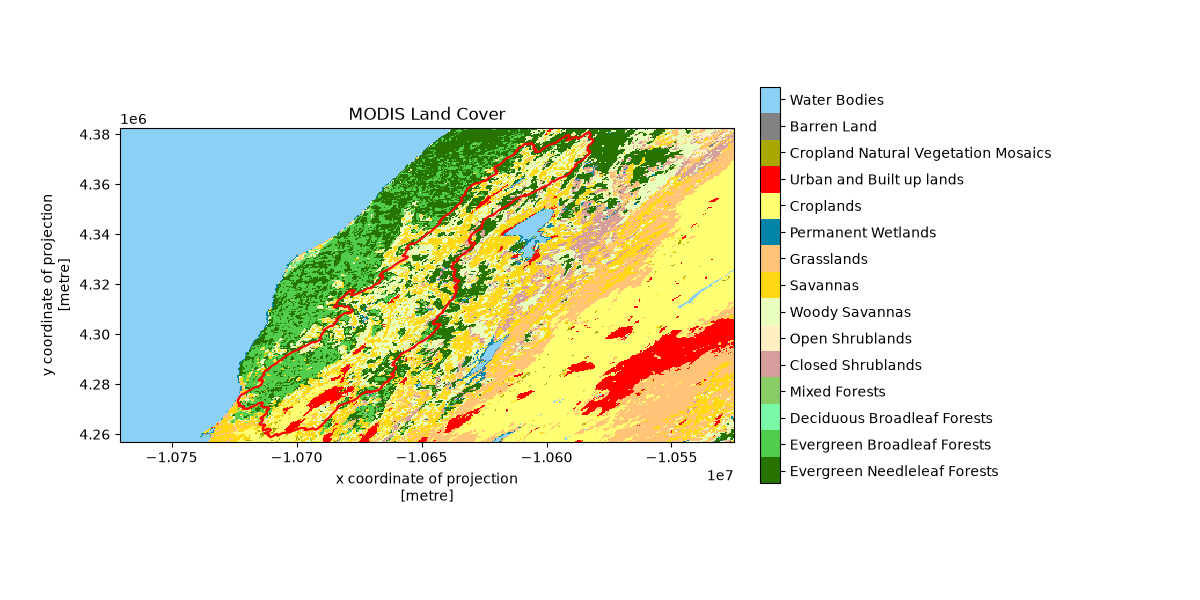

In [27]:
# create a colormap for the data -- note the native CRS for MODIS is a sinusoidal, sattelite based CRS that looks weird.
# "true north" is somewhere to the top-right corner of the box.
modis_indices, modis_cmap, modis_norm, modis_ticks, modis_labels = \
      watershed_workflow.plot.createMODISColormap(np.unique(modis_data['LULC'].values))

fig = plt.figure(figsize=(12,6))
ax = fig.add_axes([0.1, 0.1, 0.55, 0.85])

modis_data['LULC'][0].plot.imshow(ax=ax, cmap=modis_cmap, norm=modis_norm, add_colorbar=False)
watersheds.df.to_crs(watershed_workflow.crs.from_xarray(modis_data)).boundary.plot(ax=ax, color='r')

watershed_workflow.plot.createIndexedColorbar(ncolors=len(modis_indices), 
                               cmap=modis_cmap, labels=modis_labels, norm=modis_norm, ax=ax) 
ax.set_aspect('equal')
ax.set_title('MODIS Land Cover')
plt.show()


### Process

In [28]:
# MODIS data comes with time-dependent LAI AND time-dependent LULC -- just take the mode to find the most common LULC
modis_data['LULC'] = watershed_workflow.utils.computeMode(modis_data['LULC'], 'time_LULC')

# now it is safe to have only one time
modis_data = modis_data.rename({'time_LAI':'time'})


In [29]:
modis_data['LULC']

<xarray.DataArray 'LULC' (y: 271, x: 530)> Size: 287kB
array([[17, 17, 17, ...,  1,  8,  8],
       [17, 17, 17, ...,  6,  8,  8],
       [17, 17, 17, ...,  8,  1,  8],
       ...,
       [17, 17, 17, ...,  6,  7, 10],
       [17, 17, 17, ...,  7,  7,  6],
       [17, 17, 17, ...,  7,  7,  7]], shape=(271, 530), dtype=int16)
Coordinates:
  * y            (y) float64 2kB 4.257e+06 4.258e+06 ... 4.382e+06 4.382e+06
  * x            (x) float64 4kB -1.077e+07 -1.077e+07 ... -1.053e+07 -1.053e+07
    spatial_ref  int64 8B 0
Attributes:
    long_name:             Land Cover Type 1 (IGBP)
    units:                 class
    scale_factor_applied:  1
    _FillValue:            -1

<xarray.DataArray 'LAI' (time: 1233)> Size: 5kB
[1233 values with dtype=float32]
Coordinates:
  * time         (time) object 10kB 2007-08-01 00:00:00 ... 2020-12-30 00:00:00
    y            float64 8B 4.327e+06
    x            float64 8B -1.065e+07
    spatial_ref  int64 8B 0
Attributes:
    long_name:             Leaf Area Index
    units:                 m^2/m^2
    scale_factor_applied:  1


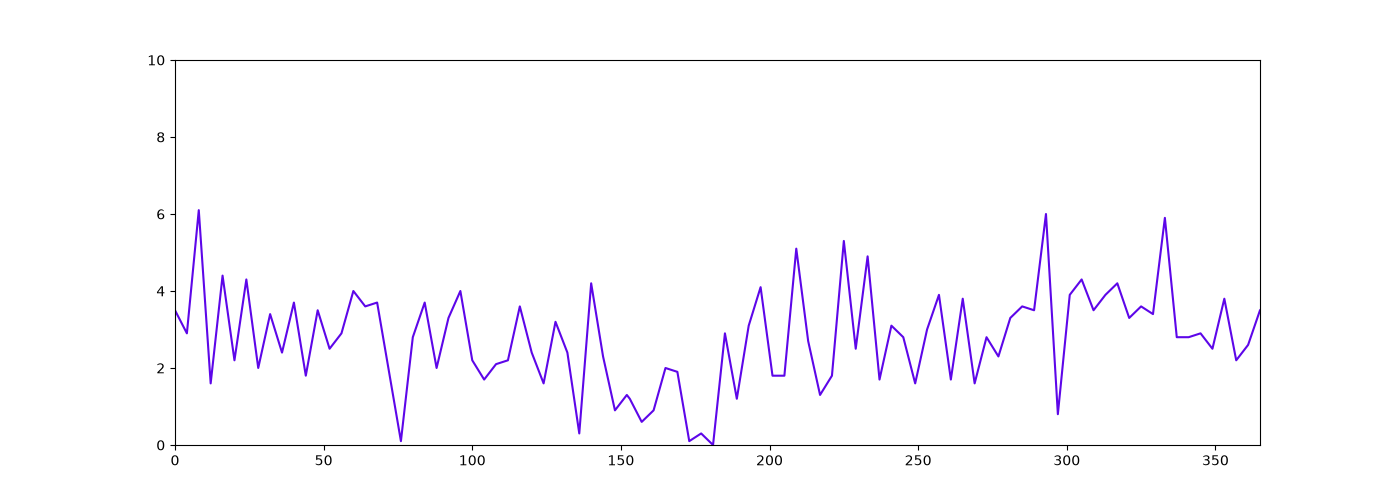

In [30]:
fig, ax = plt.subplots(figsize=(14,5))
print(modis_data['LAI'][:, 150,250])

time_xax = (modis_data['time'].values - start)
time_xax = np.array([t.days for t in time_xax])
ax.plot(time_xax, modis_data['LAI'][:, 150, 250])

ax.set_xlim(0, 365) # to zoom in to one year, convert time to nano-seconds
ax.set_ylim(0,10)
plt.show()




In [31]:
# MODIS MCD15A3H valid LAI is 0-10 (raw 0-100 * 0.1). Values 24.8-25.5 are fill codes
# (water, urban, barren, snow/ice, cloud, etc.) -- mask them out
modis_data['LAI'] = modis_data['LAI'].where(modis_data['LAI'] <= 10)

# compute the transient time series by class
modis_lai_ts = watershed_workflow.properties.land_cover.computeTimeSeries(modis_data['LAI'], modis_data['LULC'],
                                                                          polygon=watersheds.exterior, polygon_crs=watersheds.crs)

# also just compute the mean value time series
modis_lai_domain_avg_ts = modis_data['LAI'].mean(dim=('x', 'y'))

,Unclassified LAI [-],Evergreen Needleleaf Forests LAI [-],Evergreen Broadleaf Forests LAI [-],Deciduous Broadleaf Forests LAI [-],Mixed Forests LAI [-],Closed Shrublands LAI [-],Open Shrublands LAI [-],Woody Savannas LAI [-],Savannas LAI [-],Grasslands LAI [-],Permanent Wetlands LAI [-],Croplands LAI [-],Urban and Built up lands LAI [-],Cropland Natural Vegetation Mosaics LAI [-],Barren Land LAI [-],Water Bodies LAI [-],time
0,NaN,2.697632,3.999548,1.7000,3.919828,1.586764,1.157576,1.588465,1.339877,1.102105,1.311111,0.819810,0.855,1.191304,NaN,NaN,2007-08-01 00:00:00
1,NaN,2.792385,3.761123,2.1375,3.603448,1.766176,1.306061,1.795834,1.446704,1.190702,1.362963,0.842473,0.810,1.193478,NaN,NaN,2007-08-05 00:00:00
2,NaN,2.608975,3.759709,1.7250,3.773278,1.547058,1.130303,1.549818,1.314969,1.093684,1.262963,0.850080,0.880,1.206522,NaN,NaN,2007-08-09 00:00:00
3,NaN,2.395799,3.290410,2.0500,2.871552,1.708088,1.272727,1.758898,1.428037,1.185439,1.392593,0.870841,0.895,1.243478,NaN,NaN,2007-08-13 00:00:00
4,NaN,2.504444,3.616966,1.6375,3.538794,1.563235,1.136364,1.541577,1.303562,1.085087,1.300000,0.815214,0.770,1.134783,NaN,NaN,2007-08-17 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1228,NaN,1.119127,1.995516,0.6750,0.831034,0.816176,0.424242,0.701982,0.682226,0.707895,0.781482,0.530428,0.340,0.656522,NaN,NaN,2020-12-14 00:00:00
1229,NaN,1.164025,2.181669,0.7375,1.050000,0.741911,0.487879,0.667275,0.660948,0.671228,0.766667,0.614740,0.395,0.726087,NaN,NaN,2020-12-18 00:00:00
1230,NaN,1.181881,2.236037,0.7000,0.969828,0.817647,0.515152,0.733761,0.731067,0.741228,0.722222,0.638828,0.400,0.754348,NaN,NaN,2020-12-22 00:00:00
1231,NaN,1.163190,2.095684,0.8000,1.061207,0.790441,0.530303,0.709367,0.708325,0.730877,0.759259,0.710778,0.410,0.765217,NaN,NaN,2020-12-26 00:00:00


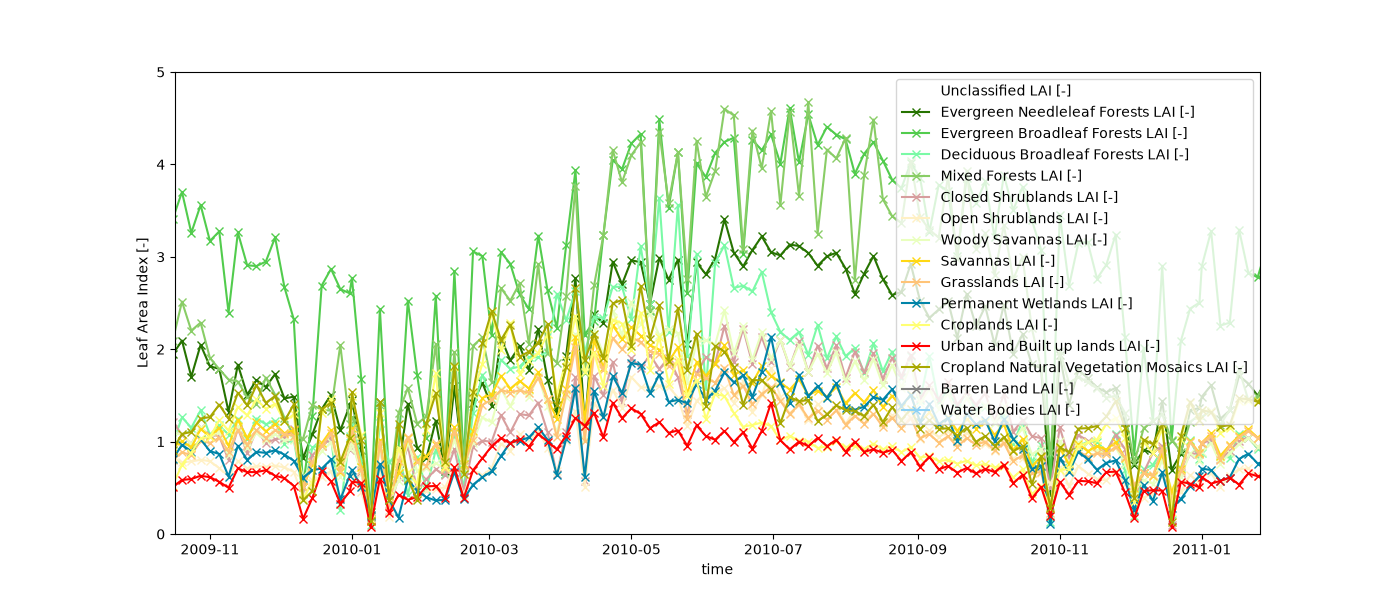

In [32]:
fig, ax = plt.subplots(figsize=(14,6))

watershed_workflow.properties.land_cover.plotLAI(modis_lai_ts, indices='MODIS', ax=ax, marker='x')
ax.set_ylim(0,5)
ax.set_xlim(14534, 15000)
modis_lai_ts

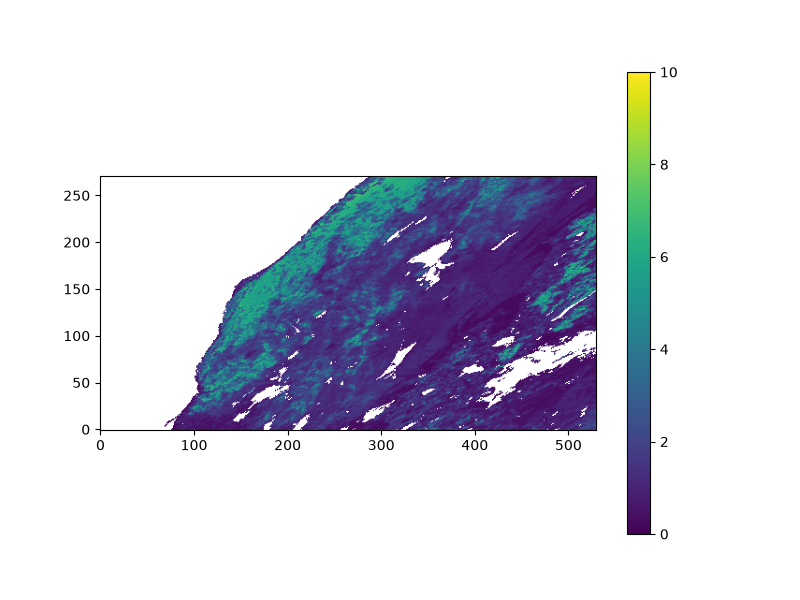

In [33]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

plt.close('all')    # ensures all figures are closed

da = modis_data['LAI']

vmin = 0.
vmax = 10.

fig, ax = plt.subplots()
im = ax.imshow(da.isel(time=0), vmin=vmin, vmax=vmax, origin="lower")
plt.colorbar(im)

def update(i):
    i = i * 10
    im.set_data(da.isel(time=i))
    ax.set_title(f"time = {da.time[i].values}")
    return (im,)

anim = FuncAnimation(fig, update, frames=len(da.time)//10, interval=500)

# --- Render to video (no live JS = no interference) ---
anim

In [34]:
anim.event_source.stop()
del anim

### Evaluate simplified models of LAI relative to full spatial-temporal data

So the first question -- is the LAI well represented by just a time series and a LULC class?

Let's compute the class-averaged LAI time series, then compare each pixel to its class-average time series, and compute spatial and temporal patterns of RMSE.

In [35]:
# compute the error made by assuming LAI is represented by the class average
error = np.array([[modis_data['LAI'][:,i,j] - modis_lai_ts[watershed_workflow.sources.manager_modis_appeears.colors[int(modis_data['LULC'][i,j])][0] + ' LAI [-]'] for j in range(modis_data['LULC'].shape[1])] for i in range(modis_data['LULC'].shape[0])])


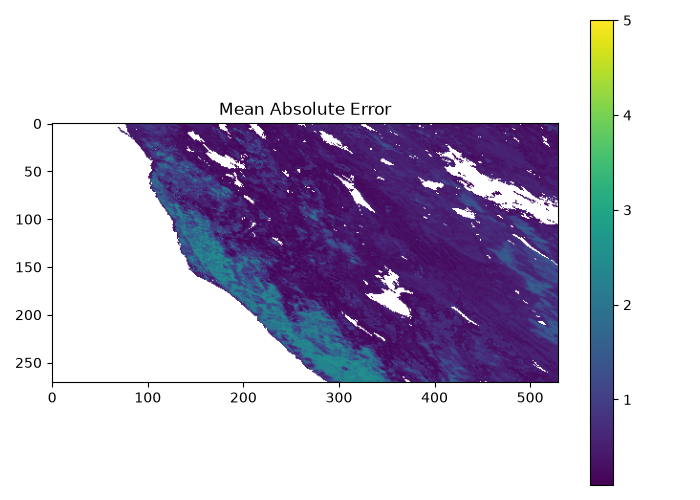

In [36]:
# Plot spatial MAE map
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(np.linalg.norm(error, ord=1, axis=2) / len(modis_lai_ts), cmap="viridis", vmax=5)
plt.colorbar(im)
ax.set_title("Mean Absolute Error")
plt.tight_layout()
plt.show()

In [37]:
# compute the error made by assuming LAI is constant across the domain
error_total = modis_data['LAI'] - modis_lai_domain_avg_ts

# this is the total variance of the LAI
V_total = (error_total**2).mean(dim=('x','y'))


In [38]:
# now compute the within-class variance
V_within  = xr.zeros_like(V_total)  # will accumulate within-class variance

# Fraction of pixels in each class
pixel_frac = modis_data['LULC'].groupby(modis_data['LULC']).count() / modis_data['LULC'].size # dict: class -> fraction

# Compute within-class variance at each time
for c in np.unique(modis_data['LULC']):
    mask = (modis_data['LULC'] == c)
    # mask LAI to only class c
    lai_c = modis_data['LAI'].where(mask)
    # compute variance over spatial dims (ignoring NaNs for masked pixels)
    var_c = lai_c.var(dim=('x', 'y'), skipna=True)
    # weight by pixel fraction
    frac_c = mask.sum() / mask.size
    V_within += frac_c * var_c

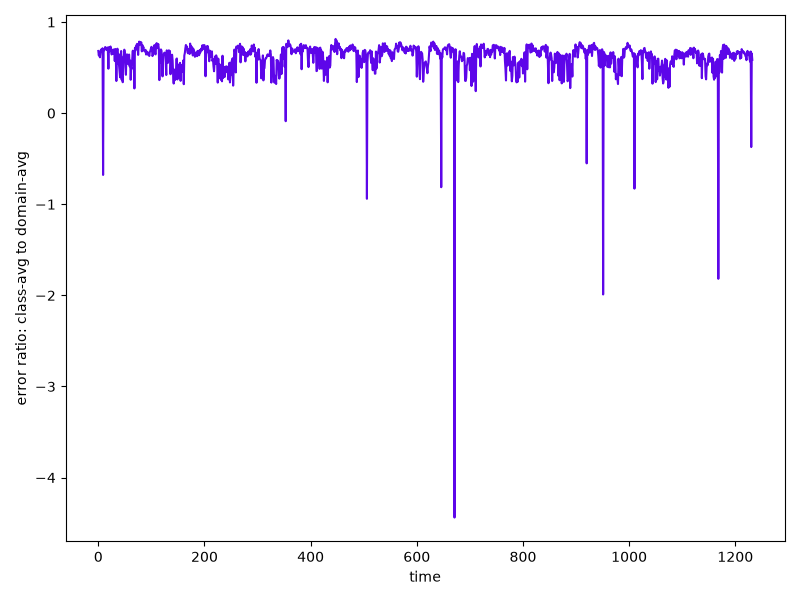

In [39]:
# plot temporal error ratio -- what is R2 of the ratio of within-class variance to total variance?
r2 = 1 - V_within / V_total

fig,ax = plt.subplots()
ax.plot(r2)
ax.set_xlabel('time')
ax.set_ylabel('error ratio: class-avg to domain-avg')
plt.tight_layout()
plt.show()

It looks like class-based is a reasonable choice for this domain -- the within-class variance is MUCH smaller than the total variance

This convinces us that class-based LAI is good enough.

(14534, 15000)

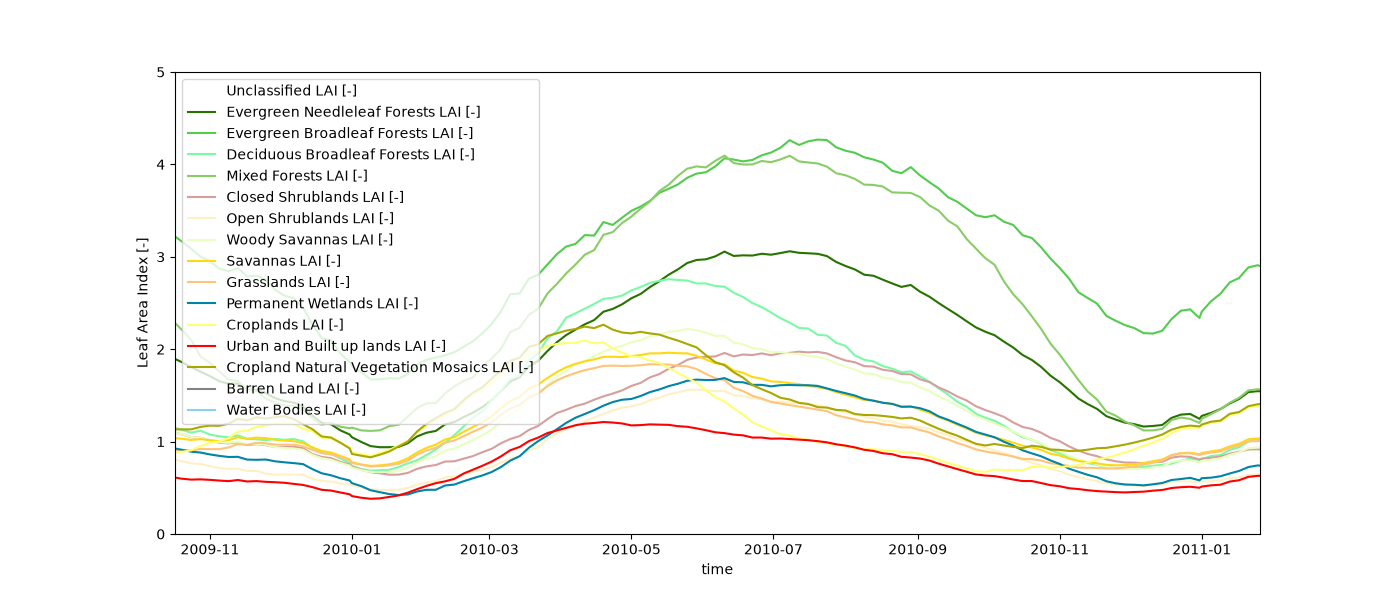

In [40]:
# smooth the data in time -- LAI has noise for some reason that I don't really believe
modis_lai_smoothed = watershed_workflow.utils.smoothTimeSeries(modis_lai_ts, 'time', window_length=31)

fig, ax = plt.subplots(figsize=(14,6))
watershed_workflow.properties.land_cover.plotLAI(modis_lai_smoothed, indices='MODIS', ax=ax)
ax.set_ylim(0,5)
ax.set_xlim(14534, 15000)

In [41]:
# limit the raw data to the window we want
modis_lai_ts_limited = modis_lai_smoothed[(modis_lai_smoothed["time"] >= start) & (modis_lai_smoothed["time"] <= end)]

# Write the transient to disk -- this still includes leap day so is good for AORC
fname_modis_lai_transient = toOutput('modis_lai_ts', f'RussianRiver_LAI_MODIS_Transient_{modis_lai_ts_limited['time'].iloc[0].year}_{modis_lai_ts_limited['time'].iloc[-1].year}.h5')
watershed_workflow.io.writeTimeseriesToHDF5(fname_modis_lai_transient, modis_lai_ts_limited)

2026-11-10 13:16:11,631 - root - INFO: Writing HDF5 file: /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/output_data/RussianRiver_LAI_MODIS_Transient_2007_2020.h5




### Continue to process for a typical year for cyclic spinup

In [42]:
# compute a typical year
modis_lai_smoothed_noleap = watershed_workflow.utils.filterLeapDay(modis_lai_smoothed)
modis_lai_typical = watershed_workflow.utils.computeAverageYear(modis_lai_smoothed_noleap,
                                                              start_date = start_noleap - datetime.timedelta(days=365*cyclic_nyears),
                                                              output_nyears=cyclic_nyears, 
                                                              )

,time,Unclassified LAI [-],Evergreen Needleleaf Forests LAI [-],Evergreen Broadleaf Forests LAI [-],Deciduous Broadleaf Forests LAI [-],Mixed Forests LAI [-],Closed Shrublands LAI [-],Open Shrublands LAI [-],Woody Savannas LAI [-],Savannas LAI [-],Grasslands LAI [-],Permanent Wetlands LAI [-],Croplands LAI [-],Urban and Built up lands LAI [-],Cropland Natural Vegetation Mosaics LAI [-],Barren Land LAI [-],Water Bodies LAI [-]
0,1997-08-01 00:00:00,NaN,2.794225,3.945311,1.988600,3.780949,1.755545,1.238285,1.741392,1.443836,1.190725,1.402213,0.894783,0.887129,1.298479,NaN,NaN
1,1997-08-05 00:00:00,NaN,2.749273,3.891207,1.943387,3.735194,1.727320,1.218685,1.711584,1.421290,1.172204,1.380619,0.881195,0.872081,1.281168,NaN,NaN
2,1997-08-09 00:00:00,NaN,2.709056,3.842377,1.905578,3.695340,1.701175,1.202903,1.684771,1.401549,1.156754,1.358977,0.872136,0.858419,1.267648,NaN,NaN
3,1997-08-13 00:00:00,NaN,2.674366,3.802303,1.876128,3.663354,1.678600,1.188709,1.660693,1.383499,1.142349,1.342243,0.862964,0.845065,1.252751,NaN,NaN
4,1997-08-17 00:00:00,NaN,2.634747,3.755655,1.836983,3.628094,1.652656,1.171160,1.633928,1.363705,1.126661,1.323602,0.853982,0.831904,1.238100,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,2007-07-12 00:00:00,NaN,2.925574,4.008325,2.182194,3.912720,1.866055,1.306604,1.848273,1.526308,1.260677,1.478911,0.953301,0.938897,1.369050,NaN,NaN
916,2007-07-16 00:00:00,NaN,2.911982,4.005801,2.148620,3.899235,1.854107,1.297988,1.835467,1.514550,1.249722,1.468594,0.938186,0.929986,1.351665,NaN,NaN
917,2007-07-20 00:00:00,NaN,2.893233,4.005197,2.110882,3.883677,1.833662,1.285809,1.816256,1.499617,1.236680,1.458774,0.927502,0.921023,1.340711,NaN,NaN
918,2007-07-24 00:00:00,NaN,2.867870,3.987985,2.076954,3.852379,1.814159,1.273541,1.796738,1.484917,1.224334,1.442735,0.917131,0.910841,1.329857,NaN,NaN


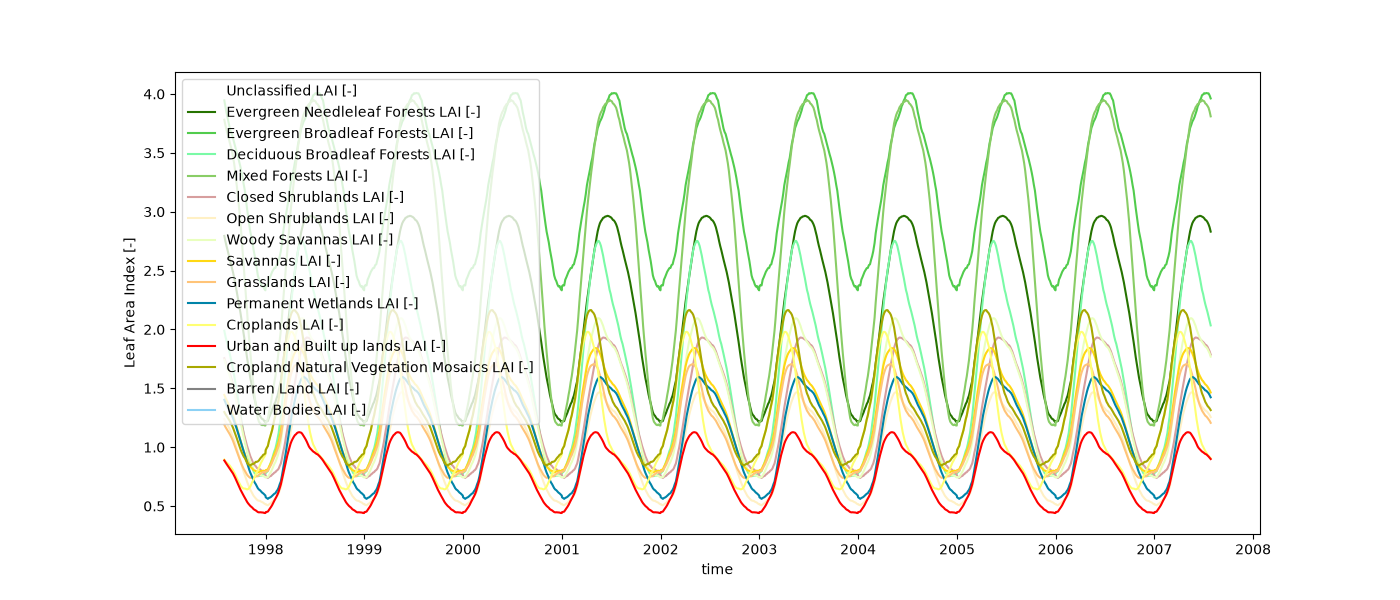

In [43]:
fig, ax = plt.subplots(figsize=(14,6))
watershed_workflow.properties.land_cover.plotLAI(modis_lai_typical, indices='MODIS', ax=ax)
modis_lai_typical

In [44]:
# limit the raw data to the window we want
modis_lai_ts_limited = modis_lai_ts[(modis_lai_smoothed["time"] >= start) & (modis_lai_smoothed["time"] <= end)]

In [45]:
modis_lai_typical['time'].iloc[-1]

cftime.DatetimeNoLeap(2007, 7, 28, 0, 0, 0, 0, has_year_zero=True)

In [46]:
# save the two time series files -- modis data
fname_modis_lai_typical = toOutput('modis_lai_typical', f'RussianRiver_LAI_MODIS_CyclicSteadystate_{modis_lai_typical['time'].iloc[0].year}_{modis_lai_typical['time'].iloc[-1].year}.h5')
watershed_workflow.io.writeTimeseriesToHDF5(fname_modis_lai_typical, modis_lai_typical)




2026-11-10 13:16:12,800 - root - INFO: Writing HDF5 file: /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/output_data/RussianRiver_LAI_MODIS_CyclicSteadystate_1997_2007.h5


## Compute the crosswalk of NLCD and MODIS

This tells us how to map MODIS LAI onto NLCD classes.

2026-11-10 13:16:13,401 - root - INFO: Compute the crosswalk between MODIS and NLCD:
2026-11-10 13:16:13,401 - root - INFO:   unique MODIS: [np.int16(1), np.int16(2), np.int16(4), np.int16(5), np.int16(6), np.int16(7), np.int16(8), np.int16(9), np.int16(10), np.int16(11), np.int16(12), np.int16(13), np.int16(14), np.int16(16), np.int16(17)]
2026-11-10 13:16:13,402 - root - INFO:   unique NLCD: [np.int16(11), np.int16(21), np.int16(22), np.int16(23), np.int16(24), np.int16(31), np.int16(41), np.int16(42), np.int16(43), np.int16(52), np.int16(71), np.int16(81), np.int16(82), np.int16(90), np.int16(95)]


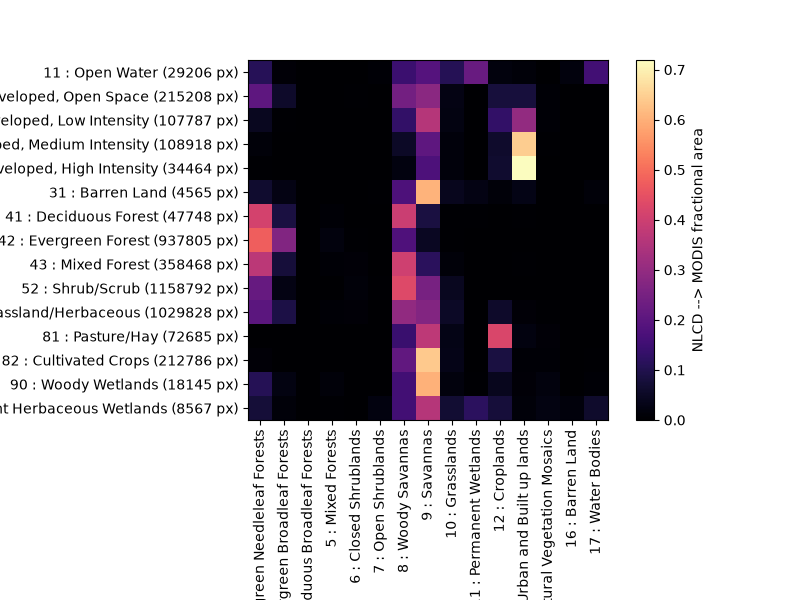

In [47]:
crosswalk = watershed_workflow.properties.land_cover.computeCrosswalk(modis_data['LULC'], nlcd, method='fractional area')

In [48]:
# Compute the NLCD-based time series
nlcd_lai_typical = watershed_workflow.properties.land_cover.applyCrosswalk(crosswalk, modis_lai_typical)
watershed_workflow.properties.land_cover.removeNullLAI(nlcd_lai_typical)


nlcd_lai_ts = watershed_workflow.properties.land_cover.applyCrosswalk(crosswalk, modis_lai_ts_limited)
watershed_workflow.properties.land_cover.removeNullLAI(nlcd_lai_ts)

nlcd_lai_ts

None LAI [-] False
Open Water LAI [-] True
Perrenial Ice/Snow LAI [-] False
Developed, Medium Intensity LAI [-] True
Developed, High Intensity LAI [-] True
Barren Land LAI [-] True
None LAI [-] False
Open Water LAI [-] True
Perrenial Ice/Snow LAI [-] False
Developed, Medium Intensity LAI [-] True
Developed, High Intensity LAI [-] True
Barren Land LAI [-] True


,time,Open Water LAI [-],"Developed, Open Space LAI [-]","Developed, Low Intensity LAI [-]","Developed, Medium Intensity LAI [-]","Developed, High Intensity LAI [-]",Barren Land LAI [-],Deciduous Forest LAI [-],Evergreen Forest LAI [-],Mixed Forest LAI [-],Shrub/Scrub LAI [-],Grassland/Herbaceous LAI [-],Pasture/Hay LAI [-],Cultivated Crops LAI [-],Woody Wetlands LAI [-],Emergent Herbaceous Wetlands LAI [-]
0,2007-08-01 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2007-08-05 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2007-08-09 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2007-08-13 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2007-08-17 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1228,2020-12-14 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1229,2020-12-18 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1230,2020-12-22 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1231,2020-12-26 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [49]:
# save the two time series files -- NLCD data
fname_nlcd_lai_typical = toOutput('nlcd_lai_typical', f'RussianRiver_LAI_NLCD_CyclicSteadystate_{nlcd_lai_typical['time'].iloc[0].year}_{nlcd_lai_typical['time'].iloc[-1].year}.h5')
watershed_workflow.io.writeTimeseriesToHDF5(fname_nlcd_lai_typical, nlcd_lai_typical)


fname_nlcd_lai_ts = toOutput('nlcd_lai_ts', f'RussianRiver_LAI_NLCD_Transient_{nlcd_lai_ts['time'].iloc[0].year}_{nlcd_lai_ts['time'].iloc[-1].year}.h5')
watershed_workflow.io.writeTimeseriesToHDF5(fname_nlcd_lai_ts, nlcd_lai_ts)

2026-11-10 13:16:14,392 - root - INFO: Writing HDF5 file: /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/output_data/RussianRiver_LAI_NLCD_CyclicSteadystate_1997_2007.h5
2026-11-10 13:16:14,396 - root - INFO: Writing HDF5 file: /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/output_data/RussianRiver_LAI_NLCD_Transient_2007_2020.h5


In [50]:
# lastly, reread, update, and output filenames
with open(toOutput('04_output_filenames', '04_output_filenames.txt'), 'wb') as fid:
    pickle.dump(output_filenames, fid)


In [51]:
nlcd_lai_ts

,time,Open Water LAI [-],"Developed, Open Space LAI [-]","Developed, Low Intensity LAI [-]","Developed, Medium Intensity LAI [-]","Developed, High Intensity LAI [-]",Barren Land LAI [-],Deciduous Forest LAI [-],Evergreen Forest LAI [-],Mixed Forest LAI [-],Shrub/Scrub LAI [-],Grassland/Herbaceous LAI [-],Pasture/Hay LAI [-],Cultivated Crops LAI [-],Woody Wetlands LAI [-],Emergent Herbaceous Wetlands LAI [-]
0,2007-08-01 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2007-08-05 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2007-08-09 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2007-08-13 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2007-08-17 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1228,2020-12-14 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1229,2020-12-18 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1230,2020-12-22 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1231,2020-12-26 00:00:00,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
